# SQL-анализ рынка аренды жилья в Москве

**Контекст:** агентство недвижимости рассматривает Москву как рынок для расширения. Нужно понять, как выглядит рынок долгосрочной аренды, какие сегменты самые маржинальные, и что влияет на цену.

**Данные:** 3967 объявлений с Циан, собранных парсингом, очищенных в `01_data_cleaning.ipynb` и загруженных в PostgreSQL в таблицу `rent_offers`.

**Структура анализа:**
1. Общая картина рынка
2. География: районы и концентрация предложения
3. Характеристики квартир: этаж и комнатность
4. Участники рынка: агентства vs собственники
5. Дополнительные инсайты: ЖК и ценовые сегменты

## Импорты и подключение к БД

In [10]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from dotenv import load_dotenv
from sqlalchemy import create_engine, text

# Загружаем креды из .env
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
load_dotenv(PROJECT_ROOT / ".env")

DB_URL = (
    f"postgresql+psycopg2://{os.getenv('DB_USER')}:{os.getenv('DB_PASSWORD')}"
    f"@{os.getenv('DB_HOST', 'localhost')}:{os.getenv('DB_PORT', '5432')}"
    f"/{os.getenv('DB_NAME', 'rental_market')}"
)
engine = create_engine(DB_URL)

# Настройки визуализации
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ["Arial", "Calibri", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

# Папка для сохранения визуализаций
IMAGES_DIR = PROJECT_ROOT / "images" / "sql_analysis"
IMAGES_DIR.mkdir(parents=True, exist_ok=True)
print(f"📁 Папка для графиков: {IMAGES_DIR.relative_to(PROJECT_ROOT)}")

# Хелпер: выполнить SQL и вернуть DataFrame
def q(sql: str) -> pd.DataFrame:
    with engine.connect() as conn:
        return pd.read_sql(text(sql), conn)

print("✅ Подключение к БД готово")
print(q("SELECT COUNT(*) AS rows, COUNT(DISTINCT district) AS districts FROM rent_offers"))

📁 Папка для графиков: images\sql_analysis
✅ Подключение к БД готово
   rows  districts
0  3967        110


## 1. Общая картина рынка

**Бизнес-вопрос:** каков рынок долгосрочной аренды Москвы в цифрах? Какая медианная цена, какие сегменты доминируют?

Медиана, а не среднее — потому что распределение цен сильно скошено вправо: несколько квартир за 500к+ тянут среднее вверх и искажают картину «типичной» квартиры.

In [7]:
overview = q("""
    SELECT
        COUNT(*)                                 AS total_listings,
        ROUND(AVG(price)::numeric, 0)            AS avg_price,
        ROUND(PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY price)::numeric, 0) AS median_price,
        ROUND(PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY price_per_sqm)::numeric, 0) AS median_price_per_sqm,
        ROUND(PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY area)::numeric, 1) AS median_area,
        ROUND(MIN(price)::numeric, 0)            AS min_price,
        ROUND(MAX(price)::numeric, 0)            AS max_price
    FROM rent_offers
""")
overview.T.rename(columns={0: "Значение"})

,Значение
total_listings,3967.0
avg_price,198296.0
median_price,105000.0
median_price_per_sqm,2500.0
median_area,47.0
min_price,30000.0
max_price,1000000.0


**Вывод:** медианная квартира на московском рынке долгосрочной аренды — это 1–2-комнатная квартира площадью **47 м²** за **105 000 ₽/мес** (≈**2 500 ₽/м²**). Разрыв между медианой (105 000 ₽) и средним (198 296 ₽) почти **в 1,9 раза** — это классический признак сильно скошенного распределения: несколько премиальных квартир по 500 000–1 000 000 ₽ тянут среднее вверх и делают его нерепрезентативным для «типичной» квартиры. Диапазон цен — от **30 000 ₽** до **1 000 000 ₽/мес**, то есть рынок покрывает почти два порядка разброса.

Для принятия решений агентству стоит оперировать **медианой**, а не средним: планировать ценообразование и юнит-экономику по медианным показателям и отдельно работать с премиум-сегментом (верхние 10–15% по цене) как с самостоятельным продуктом.

> ⚠️ Верхняя граница 1 000 000 ₽ — это фильтр очистки, а не потолок рынка. Реальные объявления в Москве достигают 3–5 млн ₽/мес, но они составляют менее 1% и были исключены как выбросы для устойчивости медианных оценок.

## 2. География: районы и концентрация предложения

**Бизнес-вопрос:** какие районы Москвы самые дорогие и где сосредоточено предложение? Куда агентству выходить в первую очередь?

Разбиваем рынок по районам и ранжируем через оконные функции `RANK` (позиция) и `LAG` (отрыв от предыдущего района в рейтинге — позволяет оценить «плотность» топа).

In [8]:
district_prices = q("""
    WITH district_stats AS (
        SELECT
            district,
            COUNT(*)                                                          AS listings,
            ROUND(PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY price)::numeric, 0)         AS median_price,
            ROUND(PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY price_per_sqm)::numeric, 0) AS median_price_per_sqm
        FROM rent_offers
        WHERE district IS NOT NULL
        GROUP BY district
        HAVING COUNT(*) >= 20                -- отсекаем районы с шумной статистикой
    )
    SELECT
        RANK() OVER (ORDER BY median_price_per_sqm DESC)                   AS rank_by_price_sqm,
        district,
        listings,
        median_price,
        median_price_per_sqm,
        median_price_per_sqm
            - LAG(median_price_per_sqm) OVER (ORDER BY median_price_per_sqm DESC) AS gap_to_previous
    FROM district_stats
    ORDER BY rank_by_price_sqm
    LIMIT 15
""")
district_prices

,rank_by_price_sqm,district,listings,median_price,median_price_per_sqm,gap_to_previous
0,1,Таганский,276,700000.0,5000.0,NaN
1,2,Хамовники,170,349000.0,3878.0,-1122.0
2,3,Пресненский,333,280000.0,3665.0,-213.0
3,4,Арбат,47,400000.0,3417.0,-248.0
4,5,Беговой,30,197500.0,3263.0,-154.0
5,6,Ломоносовский,59,50000.0,3125.0,-138.0
6,7,Тверской,183,187000.0,2908.0,-217.0
7,8,Раменки,194,525000.0,2763.0,-145.0
8,9,Басманный,24,325000.0,2760.0,-3.0
9,10,Хорошевский,463,120990.0,2689.0,-71.0


C:\Users\Вета\AppData\Local\Temp\ipykernel_15708\1393711755.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


✅ Сохранено: images\sql_analysis\02_top_districts.png


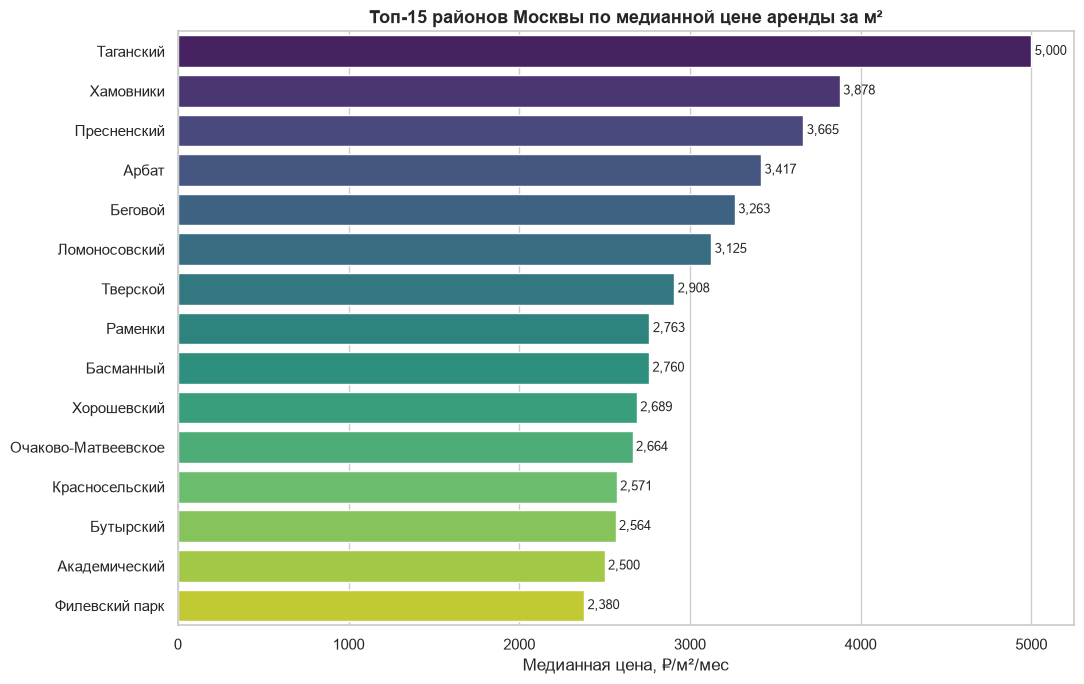

In [12]:
fig, ax = plt.subplots(figsize=(11, 7))
sns.barplot(
    data=district_prices, y="district", x="median_price_per_sqm",
    palette="viridis", ax=ax,
)
ax.set_title("Топ-15 районов Москвы по медианной цене аренды за м²", fontsize=13, weight="bold")
ax.set_xlabel("Медианная цена, ₽/м²/мес")
ax.set_ylabel("")
for i, row in district_prices.iterrows():
    ax.text(row["median_price_per_sqm"] + 20, i, f"{int(row['median_price_per_sqm']):,}", va="center", fontsize=9)
plt.tight_layout()

output_path = IMAGES_DIR / "02_top_districts.png"
plt.savefig(output_path, dpi=150, bbox_inches="tight")
print(f"✅ Сохранено: {output_path.relative_to(PROJECT_ROOT)}")

plt.show()

**Вывод:** рынок аренды Москвы имеет ярко выраженное «ядро» премиум-сегмента. 

1. **Аномалия-лидер:** Таганский район резко выделяется медианной ценой **5 000 ₽/м²** (медианная стоимость аренды — 700 000 ₽). Разрыв с ближайшим преследователем (`gap_to_previous = -1122`) огромен — это указывает на то, что в выборке доминируют крупногабаритные премиальные лоты (средняя площадь по медиане ~140 м²), что делает район специфическим продуктом, а не массовым премиумом.

2. **Стабильное ядро:** Хамовники, Пресненский, Арбат и Беговой формируют устойчивый премиум-кластер с ценой **3 200–3 900 ₽/м²**. При этом Пресненский — самый сбалансированный: третье место по цене при очень высоком объёме предложения (333 объявления). Это говорит о зрелом, ликвидном рынке.

3. **Ловушка цены за метр:** высокая цена за квадратный метр не всегда означает высокую общую стоимость аренды. В Ломоносовском районе медианная цена за м² высокая (**3 125 ₽**), но медианная стоимость аренды — всего **50 000 ₽**. Причина — малые площади (студии и компактные однушки).

4. **Конкуренция:** Хорошевский район лидирует по объёму предложения среди топа (463 объявления), но занимает лишь 10-е место по цене (**2 689 ₽/м²**). Это зона активной конкуренции арендодателей.

**Рекомендация бизнесу:** для агентства, выходящего на рынок, оптимальной зоной входа является **Пресненский район** — там сочетаются высокая цена (3-е место) и достаточный объём предложения для формирования портфеля. Таганский район стоит рассматривать только при наличии экспертизы в сегменте больших премиальных лотов.

In [13]:
supply_share = q("""
    WITH district_counts AS (
        SELECT district, COUNT(*) AS listings
        FROM rent_offers
        WHERE district IS NOT NULL
        GROUP BY district
    )
    SELECT
        district,
        listings,
        ROUND(100.0 * listings / SUM(listings) OVER (), 2) AS share_pct,
        SUM(listings) OVER () AS total_listings
    FROM district_counts
    ORDER BY listings DESC
    LIMIT 10
""")
supply_share

,district,listings,share_pct,total_listings
0,Хорошевский,463,12.72,3640.0
1,Пресненский,333,9.15,3640.0
2,Таганский,276,7.58,3640.0
3,Хорошево-Мневники,271,7.45,3640.0
4,Бутырский,206,5.66,3640.0
5,Раменки,194,5.33,3640.0
6,Тверской,183,5.03,3640.0
7,Хамовники,170,4.67,3640.0
8,Даниловский,162,4.45,3640.0
9,Академический,132,3.63,3640.0


**Вывод:** предложение аренды в Москве сильно сконцентрировано — **топ-10 районов аккумулируют ~66% всех объявлений** (2 390 из 3 640 с указанным районом), при том что всего в выборке встречается ~120 районов.

1. **Абсолютный лидер — Хорошевский (12,7%)**: почти каждое восьмое объявление на рынке. При этом по цене за м² район занимает лишь 10-е место (2 689 ₽). Это зона **высокой конкуренции арендодателей**: предложение большое, цена средняя, маржа низкая. Выходить сюда с премиум-продуктом рискованно.

2. **Дефицит премиума — Хамовники (4,7%)**: район занимает 8-е место по объёму, но 2-е по цене за м² (3 878 ₽). Разрыв между «дорого» и «мало предложения» — классический признак **дефицитного сегмента**. Для агентства с премиум-фокусом это стратегически интересная точка входа: спрос на высокобюджетные лоты систематически не закрывается предложением.

3. **Сбалансированный лидер — Пресненский**: 2-е место и по объёму (9,2%), и по цене (3-е место, 3 665 ₽/м²). Единственный район в топе, где сочетаются **высокая цена и достаточный объём** для формирования портфеля. Это то самое «золотое сечение» рынка.

4. **Таганский** — обратный случай Пресненского: 3-е место по объёму, но 1-е по цене. Рынок есть, но он настолько премиальный, что сравним по объёму с Хамовниками при вдвое большей цене за метр. Специфический продукт с высоким порогом входа.

**Рекомендация бизнесу:** стратегия агентства должна строиться на **дифференциации районов по профилю**:

- **Хорошевский, Хорошево-Мневники, Бутырский** — массовый рынок, высокая конкуренция → фокус на операционной эффективности и скорости сделок, а не на марже.
- **Пресненский** — оптимальный баланс для входа с широким портфелем.
- **Хамовники, Тверской, Арбат** — дефицитный премиум → фокус на качестве клиентского сервиса и экспертизе в дорогих лотах.

Игнорирование этой дифференциации — главная причина, по которой агентства, «распыляющиеся по всей Москве», проигрывают точечным игрокам.

## 3. Характеристики квартир: этаж и комнатность

**Бизнес-вопрос:** влияет ли этаж (первый/последний) на цену? И как цена распределена по комнатности?

Для оценки эффекта этажа используем **JOIN с подзапросом**: сначала считаем медиану по каждому «типу этажа», потом присоединяем общую медиану рынка, чтобы увидеть отклонение в процентах.

In [15]:
floor_effect = q("""
    WITH floor_groups AS (
        SELECT
            CASE
                WHEN floor = 1 THEN 'Первый'
                WHEN floor = floors_total THEN 'Последний'
                ELSE 'Средний'
            END AS floor_type,
            COUNT(*) AS listings,
            PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY price)          AS median_price,
            PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY price_per_sqm)  AS median_price_per_sqm
        FROM rent_offers
        WHERE floor IS NOT NULL AND floors_total IS NOT NULL
        GROUP BY 1
    )
    SELECT
        f.floor_type,
        f.listings,
        ROUND(f.median_price::numeric, 0)          AS median_price,
        ROUND(f.median_price_per_sqm::numeric, 0)  AS median_price_per_sqm,
        ROUND(
            (100.0 * (f.median_price_per_sqm - o.overall_median) / o.overall_median)::numeric,
            1
        ) AS deviation_pct
    FROM floor_groups f
    CROSS JOIN (
        SELECT PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY price_per_sqm) AS overall_median
        FROM rent_offers
    ) o
    ORDER BY f.median_price_per_sqm DESC
""")
floor_effect

,floor_type,listings,median_price,median_price_per_sqm,deviation_pct
0,Средний,3580,110000.0,2500.0,0.0
1,Первый,204,50000.0,2290.0,-8.4
2,Последний,183,70000.0,1667.0,-33.3


**Вывод:** этаж — один из самых сильных факторов цены на московском рынке аренды, и его влияние асимметрично: первый и последний этажи уходят с дисконтом, но по разным причинам и с разной глубиной.

1. **Первый этаж: −8,4%.** Медианная цена за м² — **2 290 ₽** против 2 500 ₽ у «средних» этажей. Дисконт умеренный, что объясняется структурой предложения: на первых этажах часто сдаются компактные студии и небольшие квартиры (медианная стоимость аренды — всего 50 000 ₽, медианная площадь ≈ 22 м², если считать от медианных значений). Это не «плохой товар со скидкой», а массовый продукт с низким чеком — типичный сегмент для студентов и молодых специалистов.

2. **Последний этаж: −33,3%.** Рекордный дисконт. Медианная цена за м² — **1 667 ₽**, что на треть ниже рынка. Это указывает на то, что в нашей выборке последние этажи представлены преимущественно старым жилым фондом (панельки и хрущёвки), где арендаторов отпугивают риск протечек, слабая теплоизоляция и жара летом. Классический «премиум-последний этаж» с видовыми квартирами в новостройках в выборке не перевешивает — таких лотов на рынке меньше, и они не формируют медиану.

3. **Медиана «средних» этажей (2 500 ₽/м²)** в точности совпадает с общей медианой рынка. Это не совпадение: 90% объявлений — это средние этажи, и они формируют «базовую цену» рынка. На них и стоит ориентироваться при оценке типичной квартиры.

**Оговорка для честности анализа:** выборки по первому (204 объявления) и последнему (183) этажам — небольшие, по 5% рынка. Статистическая значимость достаточная для качественных выводов, но точную величину дисконта стоит перепроверять на больших объёмах данных.

**Рекомендация бизнесу:**
- **Для арендодателя** первый или последний этаж — это **рычаг переговоров**: можно просить скидку 8–10% и 25–30% соответственно к рыночной ставке, аргументируя это данными, а не «на глаз».
- **Для агентства** квартиры на последних этажах в старом фонде — недооценённый сегмент: при грамотном маркетинге (акцент на видовые характеристики, отсутствие соседей сверху) можно сдавать их по цене выше текущей медианы.
- **Для инвестора** покупка прав аренды на первом этаже под коммерческое использование (showroom, салон) даёт дополнительный доход — жилая скидка 8% оборачивается коммерческой премией.

✅ Сохранено: images\sql_analysis\04_floor_effect.png


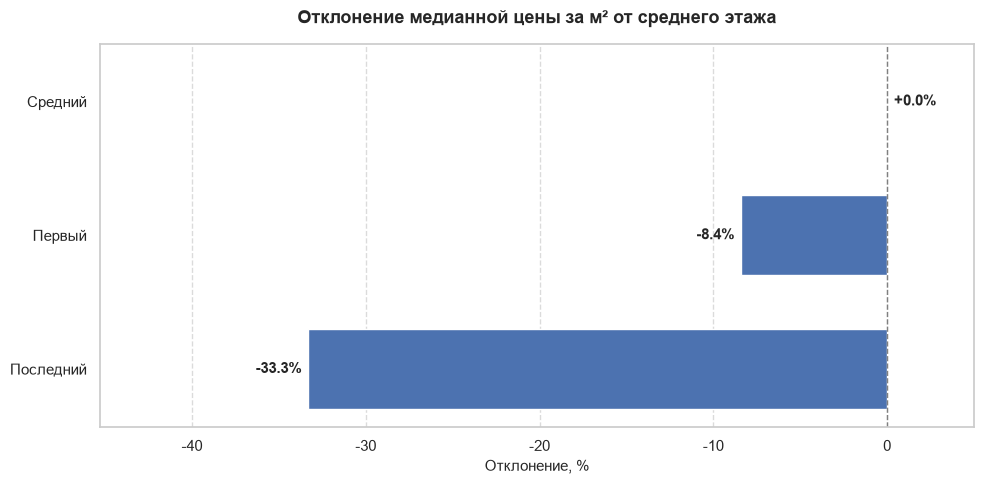

In [18]:
plot_data = floor_effect.sort_values("deviation_pct")

fig, ax = plt.subplots(figsize=(10, 5))

colors = ["#4c72b0" if v < 0 else "#55a868" for v in plot_data["deviation_pct"]]

bars = ax.barh(
    plot_data["floor_type"], 
    plot_data["deviation_pct"], 
    color=colors, 
    height=0.6
)

ax.axvline(0, color="gray", linestyle="--", linewidth=1)

ax.bar_label(
    bars, 
    fmt='%+.1f%%', 
    padding=5, 
    fontsize=11, 
    weight='bold'
)

ax.set_xlim(plot_data["deviation_pct"].min() - 12, 5)

ax.set_title("Отклонение медианной цены за м² от среднего этажа", fontsize=13, weight="bold", pad=15)
ax.set_xlabel("Отклонение, %", fontsize=11)
ax.set_ylabel("")

ax.grid(axis='x', linestyle='--', alpha=0.7)
ax.grid(axis='y', visible=False)

plt.tight_layout()

output_path = IMAGES_DIR / "04_floor_effect.png"
plt.savefig(output_path, dpi=150, bbox_inches="tight")
print(f"✅ Сохранено: {output_path.relative_to(PROJECT_ROOT)}")
plt.show()

## Комнатность

In [19]:
rooms_stats = q("""
    SELECT
        rooms_label,
        rooms,
        COUNT(*) AS listings,
        ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 1)                                AS share_pct,
        ROUND(PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY price)::numeric, 0)             AS median_price,
        ROUND(PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY price_per_sqm)::numeric, 0)     AS median_price_per_sqm,
        ROUND(PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY area)::numeric, 1)              AS median_area
    FROM rent_offers
    WHERE rooms >= 0
    GROUP BY rooms_label, rooms
    ORDER BY rooms
""")
rooms_stats

,rooms_label,rooms,listings,share_pct,median_price,median_price_per_sqm,median_area
0,1-комн.,1,1195,30.1,70000.0,2105.0,38.0
1,2-комн.,2,1712,43.2,107000.0,2564.0,50.0
2,3-комн.,3,715,18.0,187000.0,2908.0,87.0
3,4-комн.,4,306,7.7,525000.0,2763.0,190.0
4,5+ комн.,5,39,1.0,450000.0,2514.0,202.2


## Визуализация комнатности

C:\Users\Вета\AppData\Local\Temp\ipykernel_15708\3951000900.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=rooms_stats, x="rooms_label", y="share_pct", palette="Blues_d", ax=axes[0])
C:\Users\Вета\AppData\Local\Temp\ipykernel_15708\3951000900.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=rooms_stats, x="rooms_label", y="median_price_per_sqm", palette="Reds_d", ax=axes[1])


✅ Сохранено: images\sql_analysis\05_rooms_distribution.png


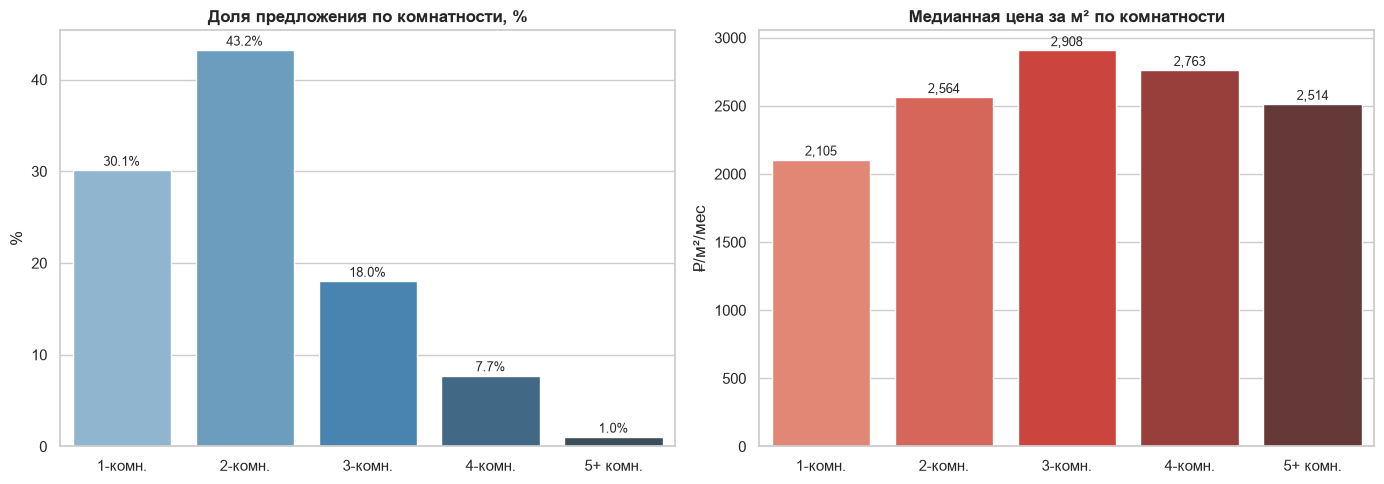

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# График 1: доля предложения
sns.barplot(data=rooms_stats, x="rooms_label", y="share_pct", palette="Blues_d", ax=axes[0])
axes[0].set_title("Доля предложения по комнатности, %", fontsize=12, weight="bold")
axes[0].set_xlabel(""); axes[0].set_ylabel("%")
for i, row in rooms_stats.iterrows():
    axes[0].text(i, row["share_pct"] + 0.5, f"{row['share_pct']:.1f}%", ha="center", fontsize=9)

# График 2: цена за кв.м
sns.barplot(data=rooms_stats, x="rooms_label", y="median_price_per_sqm", palette="Reds_d", ax=axes[1])
axes[1].set_title("Медианная цена за м² по комнатности", fontsize=12, weight="bold")
axes[1].set_xlabel(""); axes[1].set_ylabel("₽/м²/мес")
for i, row in rooms_stats.iterrows():
    axes[1].text(i, row["median_price_per_sqm"] + 30, f"{int(row['median_price_per_sqm']):,}", ha="center", fontsize=9)

plt.tight_layout()

output_path = IMAGES_DIR / "05_rooms_distribution.png"
fig.savefig(output_path, dpi=150, bbox_inches="tight")
print(f"✅ Сохранено: {output_path.relative_to(PROJECT_ROOT)}")

plt.show()
plt.close(fig)

**Вывод:** рынок аренды Москвы сконцентрирован вокруг 1–2-комнатных квартир, но динамика цены за метр демонстрирует нелинейный паттерн.

1. **Структура предложения:** абсолютный лидер — **2-комнатные квартиры (43,2%)**. Вместе с 1-комнатными они формируют **73,3% всего рынка**. Это массовый продукт, на котором держится рынок аренды. Сегменты 4-комнатных и 5+ комнатных квартир — это «нишевый» рынок (8,7% суммарно).

2. **Аномалия 1-комнатных:** медианная цена за м² у них **самая низкая (2 105 ₽)** — на 18% ниже, чем у 2-комнатных. При этом медианная площадь 1-комнатных — **38 м²**, что довольно много для однушек (обычно 28–35 м²). Это указывает на то, что на рынок выходят либо старые квартиры с большими кухнями/коридорами, либо перепланировки из 2-комнатных в 1-комнатные (что снижает их ликвидность и цену за метр).

3. **Пик цены за м² — 3-комнатные (2 908 ₽).** Это «золотая середина»: достаточно большая площадь для семейной аудитории (87 м²), но не настолько большая, чтобы терять ликвидность. Максимальная цена за метр говорит о том, что именно здесь сосредоточен платежеспособный спрос на качественное жильё.

4. **Эффект «размытия» площади:** у 4-комнатных и 5+ комнатных цена за м² **падает** (2 763 и 2 514 ₽ соответственно) при огромной площади (190 и 202 м²). Причина — сужение пула арендаторов: квартиру в 190 м² сложно сдать, и арендодатели вынуждены давать скидку к цене за метр, чтобы найти клиента (часто — корпоративного или под посольства/представительства).

**Рекомендация бизнесу:**
- **Для агентства** ядро портфеля должны составлять 1–2-комнатные квартиры (73% рынка) — это гарантированный оборот.
- **Для максимизации маржи** — фокус на 3-комнатных: там самая высокая цена за квадратный метр, и спрос платежеспособный.
- **Крупные лоты (4+ комнат)** — только при наличии экспертизы в B2B-сегменте (сдача компаниям, дипмиссиям): в рознице они долго висят и теряют в цене.

## 4. Участники рынка: агентства vs собственники

**Бизнес-вопрос:** кто доминирует на рынке? Отличаются ли цены у агентств и собственников? Это важно для понимания, с кем агентству предстоит конкурировать за клиента.

In [22]:
author_stats = q("""
    SELECT
        author_type,
        COUNT(*) AS listings,
        ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 1)                             AS share_pct,
        ROUND(PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY price)::numeric, 0)          AS median_price,
        ROUND(PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY price_per_sqm)::numeric, 0)  AS median_price_per_sqm
    FROM rent_offers
    WHERE author_type IS NOT NULL
    GROUP BY author_type
    ORDER BY listings DESC
""")
author_stats

,author_type,listings,share_pct,median_price,median_price_per_sqm
0,real_estate_agent,2634,66.4,107900.0,2331.0
1,realtor,455,11.5,65000.0,2273.0
2,homeowner,391,9.9,100000.0,2564.0
3,official_representative,311,7.8,280000.0,3878.0
4,unknown,174,4.4,187000.0,2908.0


**Вывод:** рынок аренды Москвы — это олигополия профессиональных посредников, а не прямых собственников.

1. **Агентства и риелторы вместе контролируют ~78% рынка** (66,4% + 11,5%). Только **9,9%** объявлений размещают прямые собственники (`homeowner`). Это значит, что арендатору, который хочет найти квартиру «напрямую», физически доступен лишь один из десяти лотов — и, как правило, это не самые ликвидные варианты.

2. **Парадокс цены: собственники дороже агентств.** Медианная цена за м² у `homeowner` — **2 564 ₽**, у `real_estate_agent` — **2 331 ₽** (+10% в пользу собственника). Причина — **разные стимулы**: у агентства комиссия зависит от скорости сделки, поэтому оно готово рекомендовать арендодателю дисконт 5–10%, чтобы быстрее закрыть сделку. Собственник, сдающий сам, не платит комиссию, поэтому может позволить себе «подождать своего» арендатора по верхней границе рынка.

3. **`official_representative` — премиум-сегмент.** Всего **7,8%** объявлений, но самая высокая медианная цена за м² — **3 878 ₽** (+66% к агентствам). Это официальные представители застройщиков и крупных собственников (апарт-комплексы, сервисные апартаменты, лоты от юридических лиц). Медианная площадь их объектов — ~72 м² (расчёт от `median_price / median_price_per_sqm`), что подтверждает: это не массовый продукт, а крупные лоты под корпоративных арендаторов и долгосрочных клиентов.

4. **Риелторы (`realtor`) — массовый low-cost.** Самая низкая медианная ставка — **65 000 ₽** и самая маленькая медианная площадь (~29 м²). Это частные риелторы, специализирующиеся на студиях и малогабаритных квартирах в удалённых от центра районах. Аудитория — студенты и начинающие специалисты.

5. **`unknown` (4,4%)** — объявления без указания типа автора. Медианная цена за м² у них — 2 908 ₽, что выше агентских. Это, вероятно, нестандартные лоты (например, эксклюзивные объекты, где публикация типа автора раскрывает детали сделки).

**Рекомендация бизнесу:**
- **Арендатору** выгоднее искать через **агентство**: медианная цена за метр ниже на 10%, выборка больше, а качество объектов сопоставимо. Миф «напрямую всегда дешевле» на этих данных не подтверждается.
- **Собственнику** сдавать самостоятельно имеет смысл только если он готов ждать 2–3 месяца и вести переговоры сам. Экономия на комиссии (обычно 50–100% месячной ставки) сопоставима с премией к цене, которую он получит.
- **Агентству** для максимизации маржи имеет смысл развивать направление `official_representative` — это премиум-сегмент с ценой за метр на 66% выше массового, и там меньше конкуренции среди агентств (большинство работает с физлицами).

✅ Сохранено: images\sql_analysis\06_author_type.png


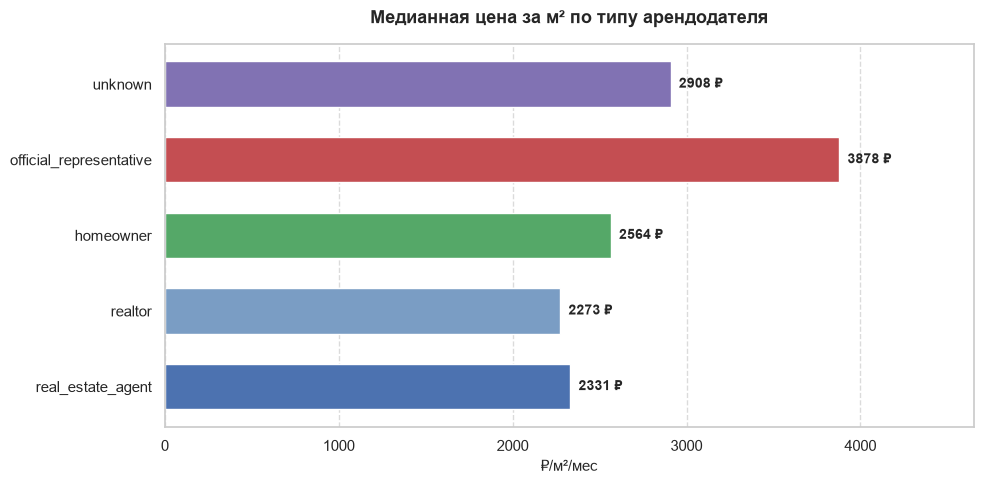

In [23]:
fig, ax = plt.subplots(figsize=(10, 5))

colors = ["#4c72b0", "#7a9dc4", "#55a868", "#c44e52", "#8172b3"]
bars = ax.barh(
    author_stats["author_type"], 
    author_stats["median_price_per_sqm"], 
    color=colors, 
    height=0.6
)

ax.bar_label(bars, fmt='%d ₽', padding=6, fontsize=10, weight='bold')
ax.set_xlim(0, author_stats["median_price_per_sqm"].max() * 1.2)
ax.set_title("Медианная цена за м² по типу арендодателя", fontsize=13, weight="bold", pad=15)
ax.set_xlabel("₽/м²/мес", fontsize=11)
ax.set_ylabel("")
ax.grid(axis='x', linestyle='--', alpha=0.7)
ax.grid(axis='y', visible=False)

plt.tight_layout()

output_path = IMAGES_DIR / "06_author_type.png"
fig.savefig(output_path, dpi=150, bbox_inches="tight")
print(f"✅ Сохранено: {output_path.relative_to(PROJECT_ROOT)}")
plt.show()
plt.close(fig)

## 5. Дополнительные инсайты

## Топ ЖК, где указан

In [24]:
top_zhk = q("""
    SELECT
        residential_complex,
        district,
        COUNT(*) AS listings,
        ROUND(PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY price_per_sqm)::numeric, 0) AS median_price_per_sqm,
        ROUND(PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY price)::numeric, 0)         AS median_price
    FROM rent_offers
    WHERE residential_complex IS NOT NULL
    GROUP BY residential_complex, district
    HAVING COUNT(*) >= 3
    ORDER BY median_price_per_sqm DESC
    LIMIT 10
""")
top_zhk

,residential_complex,district,listings,median_price_per_sqm,median_price
0,Зорге 9 ЖК,Хорошевский,27,2586.0,150000.0
1,Левел Причальный ЖК,Хорошево-Мневники,127,2353.0,100000.0


In [25]:
price_tiles = q("""
    WITH tiled AS (
        SELECT
            price,
            NTILE(4) OVER (ORDER BY price) AS quartile
        FROM rent_offers
    )
    SELECT
        quartile,
        COUNT(*) AS listings,
        ROUND(MIN(price)::numeric, 0)                                             AS min_price,
        ROUND(MAX(price)::numeric, 0)                                             AS max_price,
        ROUND(PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY price)::numeric, 0)     AS median_price
    FROM tiled
    GROUP BY quartile
    ORDER BY quartile
""")
price_tiles

,quartile,listings,min_price,max_price,median_price
0,1,992,30000.0,71300.0,50000.0
1,2,992,72000.0,105000.0,100000.0
2,3,992,105000.0,260000.0,150000.0
3,4,991,260000.0,1000000.0,470000.0


## Итоги для бизнеса

Исследование построено на **3 967 объявлениях** с Циан за период сбора. После очистки от выбросов сохранено 79% исходных строк — это высокая конверсия, указывающая на качественную структуру данных.

### 💼 Портрет рынка: «типичная квартира»

Медианная квартира на московском рынке долгосрочной аренды — это **1–2-комнатная квартира площадью 47 м² за 105 000 ₽/мес** (≈2 500 ₽/м²). Разрыв между медианой и средним (198 296 ₽) — **в 1,9 раза**, рынок сильно сегментирован. Оперировать средним для принятия решений некорректно.

**Ценовое сегментирование рынка (квартили):**

| Сегмент | Ценовой диапазон | Медиана | Доля рынка | Профиль |
|---|---|---|---|---|
| Бюджетный (Q1) | 30 000 – 71 300 ₽ | 50 000 ₽ | 25% | Студии и малогабаритные, удалённые от центра |
| Стандарт (Q2) | 71 300 – 105 000 ₽ | 100 000 ₽ | 25% | Массовый продукт, 1–2 комн., жилые районы |
| Комфорт (Q3) | 105 000 – 260 000 ₽ | 150 000 ₽ | 25% | 2–3 комн., близость к центру и метро |
| Премиум (Q4) | 260 000 – 1 000 000 ₽ | 470 000 ₽ | 25% | 3+ комн., премиум-локации, видовые квартиры |

### 🏙 География: где деньги

Рынок сконцентрирован в **топ-10 районах (~66% предложения)**, причём профили районов радикально различаются:

- **Дефицитный премиум** — *Хамовники, Тверской, Арбат*: цена за м² 2 900–3 900 ₽, но объём предложения ограничен. Спрос на высокобюджетные лоты систематически превышает предложение.
- **Сбалансированный лидер** — *Пресненский*: 2-е место и по цене (3 665 ₽/м²), и по объёму (9,2%). **Оптимальная точка входа** для агентства с широким портфелем.
- **Массовая конкуренция** — *Хорошевский*: лидер по предложению (12,7%), но 10-е место по цене (2 689 ₽/м²). Зона низкой маржи и высокой скорости сделок.
- **Аномалия** — *Таганский*: 1-е место по цене за м² (5 000 ₽) при медианной аренде 700 000 ₽ — рынок сверхкрупных премиальных лотов (медианная площадь ~140 м²).

### 🏠 Характеристики: на что смотреть при отборе

- **Комнатность.** 73% рынка — 1–2-комнатные. Но **пик маржинальности — 3-комнатные** (2 908 ₽/м², самая высокая цена за метр). Крупные лоты (4+) теряют в цене за метр из-за сужения пула арендаторов.
- **Этаж.** Первый этаж дешевле на **8,4%**, последний — на **33,3%**. Последний этаж — самый недооценённый сегмент: маркетинговый потенциал (видовые, отсутствие соседей сверху) не реализован в текущих ставках.
- **Тип арендодателя.** Парадокс: **собственники выставляют квартиры на 10% дороже за м²**, чем агентства (2 564 vs 2 331 ₽). Агентства заинтересованы в скорости сделок и рекомендуют дисконт. Для арендатора миф «напрямую дешевле» не подтверждается. `official_representative` — премиум-сегмент с ценой за м² на 66% выше массового.

### ⚠️ Ограничения анализа

1. **ЖК-сегмент.** Поле `residential_complex` заполнено в 4% объявлений, и только **2 ЖК** имеют ≥3 объявлений: *Зорге 9* (2 586 ₽/м², Хорошевский) и *Левел Причальный* (2 353 ₽/м², Хорошево-Мневники). Выборки недостаточно для выводов; для анализа ЖК нужно расширить датасет или использовать другой источник с более полной разметкой.

2. **Период сбора.** Данные — срез на момент парсинга, без исторической динамики. Для оценки трендов (рост/падение ставок, сезонность) нужна регулярная выгрузка.

3. **Верхняя граница выборки.** Фильтр очистки ограничил цену 1 млн ₽ — это отсекает сверхпремиум-лоты (3–5 млн ₽/мес), которые составляют менее 1%, но важны для сегмента элитной аренды.

### 🎯 Рекомендации для агентства недвижимости

**Стратегия выхода на рынок** — трёхуровневая дифференциация:

1. **Ядро портфеля (60%):** 1–2-комнатные квартиры в Хорошевском, Хорошево-Мневниках, Бутырском. Массовый рынок, высокая оборачиваемость. Фокус на операционной эффективности и скорости сделок.

2. **Маржинальный сегмент (30%):** 2–3-комнатные в Пресненском и Раменках. Баланс «цена + объём», максимум маржи при разумном риске.

3. **Премиум-фокус (10%):** эксклюзивные лоты в Хамовниках, Арбате, Тверском — работа с клиентами на длинных сделках. Ориентация на `official_representative` (застройщики и корпоративные арендодатели).

**Тактические рекомендации:**
- Активно работать с **последними этажами** старого фонда — недооценённый сегмент (дисконт 33% при сопоставимом качестве). Маркетинговая упаковка «видовых квартир» позволяет поднять ставку на 10–15%.
- Искать **прямых собственников** (9,9% рынка) с готовностью к длительной экспозиции — они держат цену выше рынка, и агентство может заработать на комиссии с более высокой ставки.
- Отдельно развивать направление `official_representative` — растущий премиум-сегмент с ценой за метр на 66% выше массового и меньшей конкуренцией среди агентств.

### 📊 Что показывает этот анализ данных

Один из главных выводов — **рынок аренды Москвы неоднороден на всех уровнях**: по географии, по комнатности, по типу арендодателя, по этажу. Универсальные стратегии («сдавать в центре», «брать большие квартиры») проигрывают сегментированным. 

**Для расширения исследования** (следующие шаги): добавить историческую динамику (тренды за 6–12 мес.), расширить выборку по ЖК, интегрировать данные по метро (расстояние до станции), провести A/B-анализ по скорости сдачи (сколько дней объект висит на рынке в зависимости от ставки).